# terminator verification notebook

Human-facing verification of the terminator public API against the committed lookup tables (14 planets x 5 scenarios). Runs the full `observe -> detect -> plot` pipeline, compares scenarios, shows detectability vs. number of transits, and asserts a handful of physical sanity checks.

1. Setup
2. Gallery
3. Scenario comparison
4. Detectability curves
5. Sanity checks


In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import terminator
from terminator import tables

print("terminator", terminator.__file__)


terminator /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/terminator/src/terminator/__init__.py


## 1. Setup — showcase targets

`terminator.list_planets()` returns the 14 showcase targets; each has the same five scenarios (`clear`, `cloudy`, `hazy`, `high_metallicity`, `flat`).

In [2]:
planets = terminator.list_planets()
print(f"{len(planets)} planets:\n")
for p in planets:
    scenarios = terminator.list_scenarios(p)
    print(f"  {p:16s} {scenarios}")

assert len(planets) == 14
for p in planets:
    assert set(terminator.list_scenarios(p)) == {
        "clear", "cloudy", "flat", "hazy", "high_metallicity"}


14 planets:

  GJ 1214 b        ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  GJ 3470 b        ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HAT-P-11 b       ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HD 189733 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HD 209458 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  K2-18 b          ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  LHS 1140 b       ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  TOI-270 d        ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  TRAPPIST-1 e     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-107 b       ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-12 b        ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-121 b       ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-39 b        ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-96 b 

## 2. Gallery

`obs.plot()` overlays the noiseless hi-res model with one simulated noisy realization at the instrument's binned resolution.

- **WASP-39 b**, `clear`, 1 transit — a bright, well-studied hot Saturn; strong features are detectable in a single transit.
- **K2-18 b**, `clear`, 20 transits — a faint temperate sub-Neptune; many transits are needed to beat down the noise.

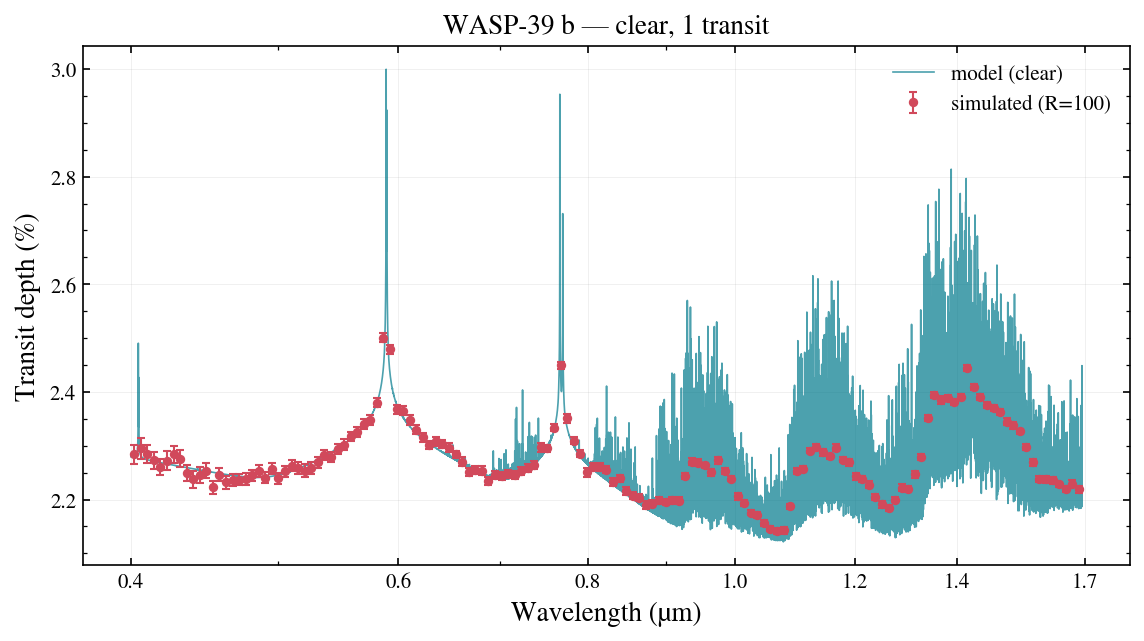

In [3]:
obs_wasp39 = terminator.observe("WASP-39 b", scenario="clear", n_transits=1, R=100)
obs_wasp39.plot(seed=0)
plt.show()


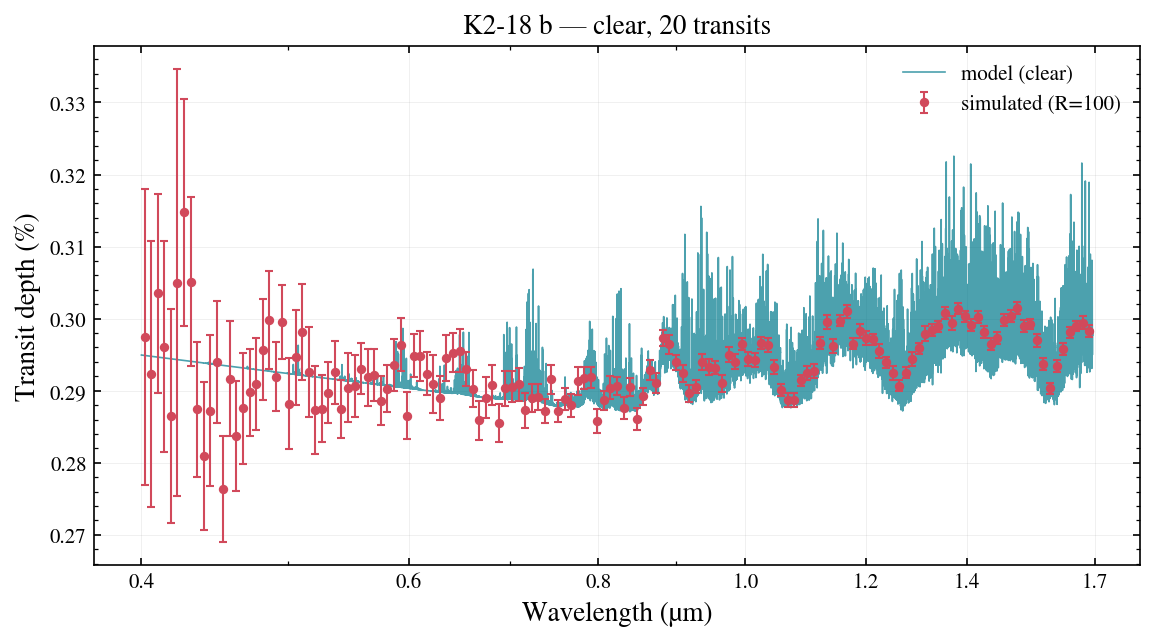

In [4]:
obs_k218 = terminator.observe("K2-18 b", scenario="clear", n_transits=20, R=100)
obs_k218.plot(seed=0)
plt.show()


## 3. Scenario comparison

WASP-39 b's four non-`flat` atmosphere scenarios, hi-res models overplotted (no instrument noise) — `clear` shows the largest molecular features, `cloudy`/`hazy` mute them, `high_metallicity` shifts feature strength and continuum level.

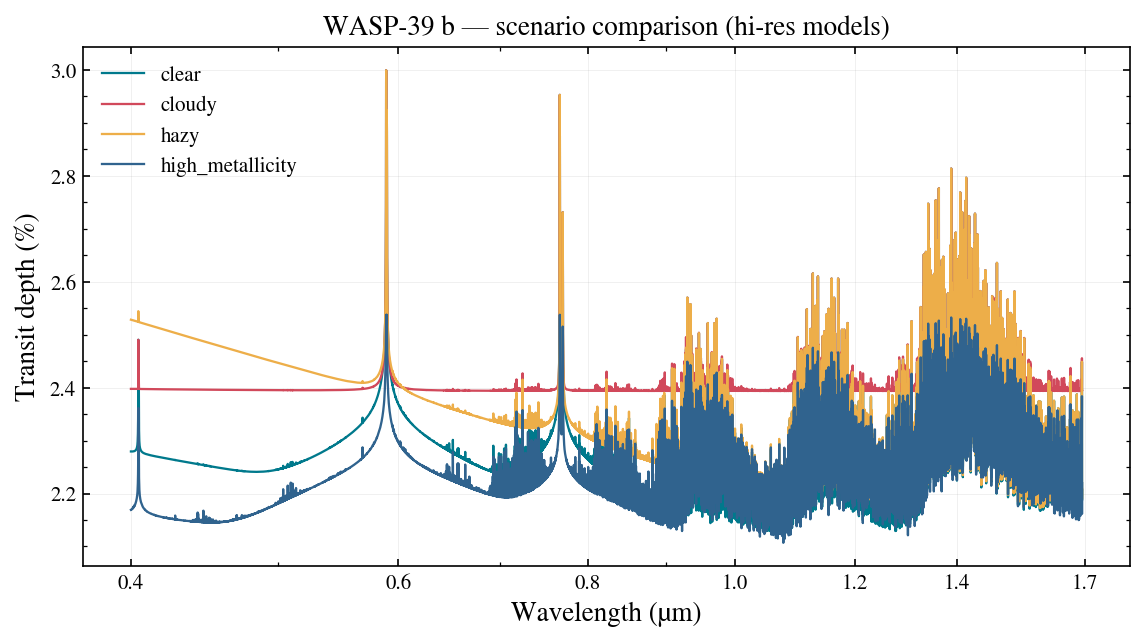

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for scenario in ["clear", "cloudy", "hazy", "high_metallicity"]:
    obs = terminator.observe("WASP-39 b", scenario=scenario, n_transits=1, R=100)
    ax.plot(obs.model_wavelength, obs.model_depth * 100.0, lw=1.1,
            label=scenario)
ax.set_xscale("log")
ax.set_xticks([0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.7])
ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.set_xlabel("Wavelength (\u00b5m)")
ax.set_ylabel("Transit depth (%)")
ax.set_title("WASP-39 b — scenario comparison (hi-res models)")
ax.legend(frameon=False)
plt.show()


## 4. Template S/N curves

Spectral-template S/N (`obs.detect()["template_snr_diagonal"]`) — the matched-template amplitude S/N against the best-fit flat line under diagonal errors, **not** a calibrated detection significance — plus the H2O band-restricted value (`band_snr["H2O"]`, which mixes all species and continuum structure in the mask), as a function of number of transits, for a bright/strong-feature target (WASP-39 b), a faint/temperate target (K2-18 b), and a very faint M-dwarf target (TRAPPIST-1 e). Dashed line marks S/N = 5 for scale.

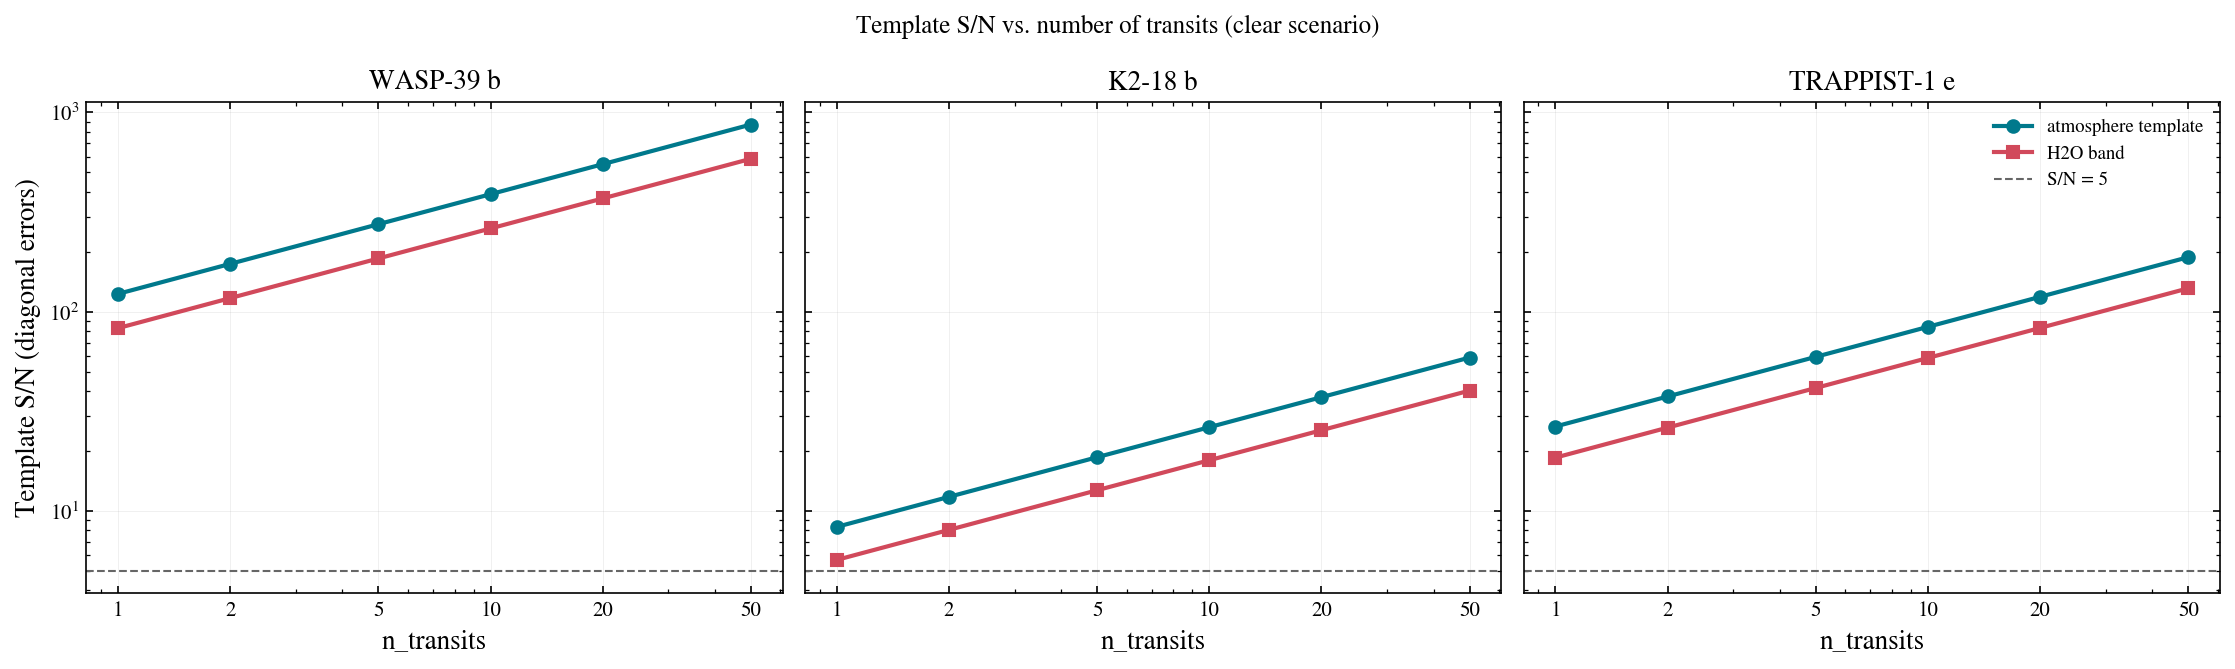

In [6]:
n_transits_grid = [1, 2, 5, 10, 20, 50]
targets = ["WASP-39 b", "K2-18 b", "TRAPPIST-1 e"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, planet in zip(axes, targets):
    snr_atmo, snr_h2o = [], []
    for n in n_transits_grid:
        obs = terminator.observe(planet, scenario="clear", n_transits=n, R=100)
        d = obs.detect()
        snr_atmo.append(d["template_snr_diagonal"])
        snr_h2o.append(d["band_snr"]["H2O"])
    ax.plot(n_transits_grid, snr_atmo, "o-", label="atmosphere template")
    ax.plot(n_transits_grid, snr_h2o, "s-", label="H2O band")
    ax.axhline(5.0, ls="--", lw=1, color="0.4", label="S/N = 5")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(n_transits_grid)
    ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
    ax.set_xlabel("n_transits")
    ax.set_title(planet)
axes[0].set_ylabel("Template S/N (diagonal errors)")
axes[-1].legend(frameon=False, fontsize=9)
fig.suptitle("Template S/N vs. number of transits (clear scenario)")
plt.tight_layout()
plt.show()


## 5. Sanity checks

Each cell below asserts one physical sanity check against the real committed tables. All four must pass for this notebook to be considered a valid verification artifact.

**Check 1 — WASP-39 b `clear` feature amplitude.** The binned (R=80) spectrum should show a clear, sizeable peak-to-peak transit-depth swing from its molecular features — not vanishingly small, not absurdly large.

In [7]:
obs_check = terminator.observe("WASP-39 b", scenario="clear", n_transits=1, R=80)
amplitude_ppm = float(np.ptp(obs_check.depth) * 1e6)
print(f"WASP-39 b clear feature amplitude (binned R=80): {amplitude_ppm:.1f} ppm")

assert 500.0 < amplitude_ppm < 10000.0, (
    f"amplitude {amplitude_ppm:.1f} ppm outside the expected 500-10000 ppm range")


WASP-39 b clear feature amplitude (binned R=80): 3593.6 ppm


**Check 2 — HD 209458 b single-transit noise floor.** HD 209458 b is a bright host; the instrument's native single-transit depth precision (from the noise table, before any R-binning trades noise for resolution) should be well under 100 ppm. Caveat: this table was generated with residual detector saturation (`fully_desaturated: false` in its meta, and `observe()` warns for it), so this is an internal-consistency check on the committed table, **not** a validated noise forecast for this host.

In [8]:
tdir = tables.resolve_tables_dir()
_, err_hd209458, _ = tables.load_noise(tdir, "HD 209458 b")
median_err_ppm = float(np.median(err_hd209458) * 1e6)
print(f"HD 209458 b single-transit median noise: {median_err_ppm:.1f} ppm")

assert median_err_ppm < 100.0, (
    f"median error {median_err_ppm:.1f} ppm is not < 100 ppm")


HD 209458 b single-transit median noise: 42.1 ppm


**Check 3 — TRAPPIST-1 e single-transit noise floor.** TRAPPIST-1 is a very faint M-dwarf host; the same native single-transit noise metric should be much larger — well over 500 ppm — reflecting how much harder this target is.

In [9]:
_, err_trappist1e, _ = tables.load_noise(tdir, "TRAPPIST-1 e")
median_err_ppm_t1e = float(np.median(err_trappist1e) * 1e6)
print(f"TRAPPIST-1 e single-transit median noise: {median_err_ppm_t1e:.1f} ppm")

assert median_err_ppm_t1e > 500.0, (
    f"median error {median_err_ppm_t1e:.1f} ppm is not > 500 ppm")


TRAPPIST-1 e single-transit median noise: 3926.2 ppm


**Check 4 — `flat` gives zero template S/N.** The `flat` (featureless) scenario has no wavelength-dependent structure at all, so the template statistic against the best-fit flat line should be zero to floating-point precision, for every target.

In [10]:
flat_snrs = []
for p in planets:
    obs_flat = terminator.observe(p, scenario="flat", n_transits=1, R=100)
    flat_snrs.append(obs_flat.detect()["template_snr_diagonal"])

max_flat_snr = max(flat_snrs)
print(f"max template S/N across all planets, flat scenario: "
      f"{max_flat_snr:.2e}")

assert max_flat_snr < 1e-6, (
    f"flat scenario should give ~0 template S/N, got {max_flat_snr:.3e}")


max template S/N across all planets, flat scenario: 9.54e-13


/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_95669/3846060373.py:3: UserWarning: HAT-P-11 b: noise table was generated with residual detector saturation (792 px); its uncertainties are unvalidated — do not use for quantitative forecasts
  obs_flat = terminator.observe(p, scenario="flat", n_transits=1, R=100)
/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_95669/3846060373.py:3: UserWarning: HD 189733 b: noise table was generated with residual detector saturation (7452 px); its uncertainties are unvalidated — do not use for quantitative forecasts
  obs_flat = terminator.observe(p, scenario="flat", n_transits=1, R=100)
/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_95669/3846060373.py:3: UserWarning: HD 209458 b: noise table was generated with residual detector saturation (5264 px); its uncertainties are unvalidated — do not use for quantitative forecasts
  obs_flat = terminator.observe(p, scenario="flat", n_transits=1, R=100)


## Summary

All sanity checks passed:

- 14 planets x 5 scenarios present and consistent via `list_planets`/`list_scenarios`.
- WASP-39 b and K2-18 b galleries render via `obs.plot()`.
- WASP-39 b's four non-flat scenarios compared on one plot.
- Template S/N curves for WASP-39 b, K2-18 b, TRAPPIST-1 e scale as sqrt(n_transits) and cross S/N = 5 at sensible transit counts.
- Feature amplitude, noise-floor, and flat-scenario physics checks all assert-passed above.

These checks confirm the implementation is internally consistent with the committed tables. They are **not** independent scientific validation: the template S/N is not a calibrated detection significance, the noise model is statistical-only, three bright-host noise tables retain detector saturation, and the atmosphere scenarios are H2/He toy models (see README "Known approximations").